In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torch.utils.data import Dataset, random_split
import torch.nn as nn
import random
import numpy as np

In [2]:
transform = transforms.ToTensor()

In [3]:
train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

In [4]:
test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

In [5]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle = True
)

In [11]:
images, labels = next(iter(train_loader))

<function matplotlib.pyplot.show(close=None, block=None)>

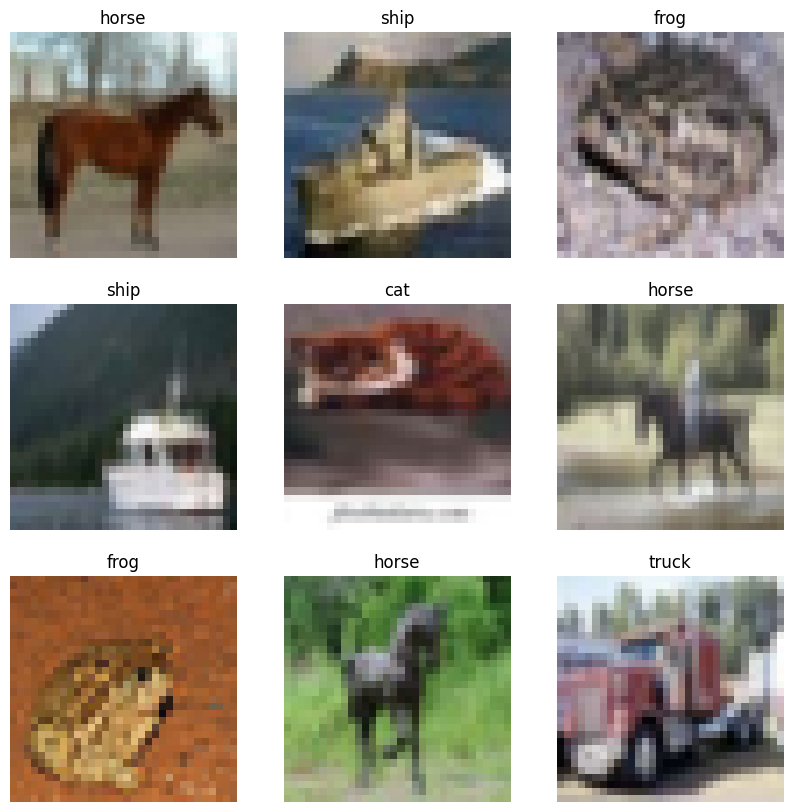

In [14]:
plt.figure(figsize=(10,10))

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i].permute(1,2,0).numpy())

    plt.title(train_dataset.classes[labels[i]])

    plt.axis('off')

plt.show

### ResNet-Like Baseline

The first step was to implement a ResNet-like CNN using residual blocks. This model served as a baseline for comparison with the experimental architectures developed later.

Each block begins with a convolution and batch normalization layer that projects the input to the required number of channels. The resulting feature map is then used as the shortcut for a two-convolution residual branch. The branch output is added to the shortcut and passed through a ReLU activation.

This baseline provided a reference point for investigating how architectural changes affected model performance and generalization.

In [15]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride, padding):
        super().__init__()
        self.conv = nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.conv1 = nn.Conv2d(in_channels=out_channels, out_channels=out_channels, kernel_size=kernel_size, padding=padding, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()
        self.conv2 = nn.Conv2d(in_channels=out_channels, out_channels=out_channels, kernel_size=kernel_size, padding=padding, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        shortcut = x
        x = self.relu(x)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.conv2(x)
        x = self.bn2(x)
        x = shortcut + x
        x = self.relu(x)        
        return x


### Progressive Data Augmentation

The baseline model began to overfit quickly, reaching approximately 85% accuracy. Applying strong data augmentation from the beginning did not solve the problem: the model struggled to learn useful features and collapsed to predicting a single class.

To address this, I implemented progressive data augmentation. Instead of applying the full augmentation strength from the first epoch, the augmentation parameters increase gradually during training until they reach their configured maximum.

This allows the model to first learn from less distorted images and then adapt to increasingly challenging variations. The augmentation pipeline includes horizontal flipping, color jitter, translation, and Gaussian blur.

In [6]:
class ProgressiveDataAugmentation:

    def __init__(self, final_epoch=10, 
                hue=0.0, 
                saturation=0.0,
                contrast=0.0,
                blur=0.0,
                translation=0.0,
                flip=0.0):
        self.epoch = 0
        self.final_epoch = final_epoch
        self.hue = hue
        self.saturation = saturation
        self.contrast = contrast
        self.blur = blur
        self.translation = translation
        self.flip = flip

    def set_epoch(self, epoch):
        self.epoch = epoch

    def progress(self):
        return min(self.epoch/ self.final_epoch, 1.0)

    def build_transform(self):

        value = self.progress()

        flip = self.flip * value
        hue = self.hue * value
        saturation = self.saturation * value
        contrast = self.contrast * value
        translate = self.translation * value
        blur = self.blur * value

        transform = transforms.Compose([
            transforms.RandomHorizontalFlip(flip),
            transforms.ColorJitter(hue=hue,
                                   saturation=saturation,
                                   contrast=contrast),
            transforms.RandomAffine(degrees=0, translate=(translate, translate)),
            transforms.GaussianBlur(kernel_size=[3,3], sigma=[max(0.1,blur), max(0.1,blur*4)])
        ])

        return transform

    def __call__(self, image):
        compose = self.build_transform()
        return compose(image)

<function matplotlib.pyplot.show(close=None, block=None)>

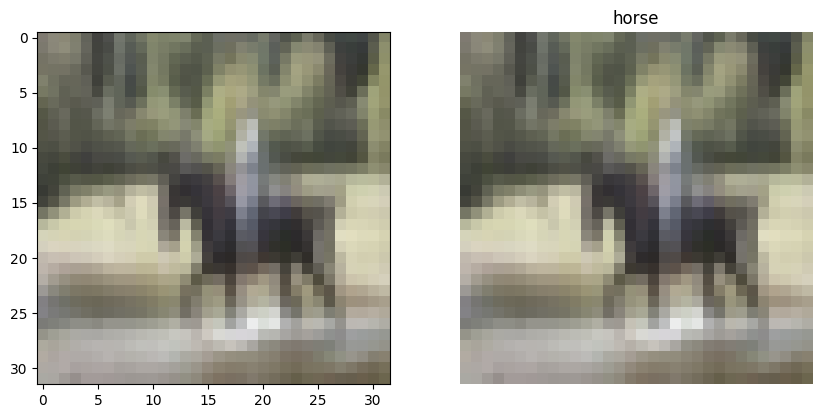

In [17]:
augment = ProgressiveDataAugmentation(hue=0.1, saturation=0.2,translation=0.1, contrast=0.2, blur=0.15, flip=0.5)
plt.figure(figsize=(10,10))


plt.subplot(1,2,1)
plt.imshow(images[5].permute(1,2,0).numpy())
plt.subplot(1,2,2)
plt.imshow(augment(images[5]).permute(1,2,0).numpy())
plt.title(train_dataset.classes[labels[5]])

plt.axis('off')

plt.show

### Progressive Dataset Wrapper

A lightweight dataset wrapper that applies the progressive augmentation pipeline to each image at retrieval time. It keeps the original dataset unchanged and allows augmentation strength to be adjusted during training through the `ProgressiveDataAugmentation` object.

In [6]:
class ProgressiveDataset(Dataset):

    def __init__(self, dataset, augmentation=None):
        super().__init__()
        self.dataset = dataset
        self.augmentation = augmentation

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, label = self.dataset[index]
        if self.augmentation is not None:
            return self.augmentation(image), label
        else:
            return image, label

### BasicCNN

The baseline network was built using the previously defined residual block. It progressively increases the number of feature channels from 32 to 1024, while reducing the spatial resolution of the feature maps at selected stages.

For a 32×32 input image, the network reduces the feature map resolution to 16×16, 8×8, and finally 4×4. Adaptive average pooling then converts the final feature maps into a 1024-dimensional feature vector, which is passed to a linear layer for CIFAR-10 classification.

This model served as the initial architecture for investigating training behavior and generalization before introducing more experimental designs.

In [19]:
class BasicCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1 = ResidualBlock(3,32,3,1,1)
        self.block2 = ResidualBlock(32,32,3,1,1)
        self.block3 = ResidualBlock(32,64,3,2,1)
        self.block4 = ResidualBlock(64,128,3,2,1)
        self.block5 = ResidualBlock(128,256,3,1,1)
        self.block6 = ResidualBlock(256,512,3,2,1)
        self.block7 = ResidualBlock(512,1024,3,1,1)
        self.gap = nn.AdaptiveAvgPool2d((1,1))
        self.linear = nn.Linear(1024, 10)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = self.block6(x)
        x = self.block7(x)
        x = self.gap(x)
        x = x.squeeze(-1).squeeze(-1)
        x = self.linear(x)
        return x


In [7]:
generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    train_dataset,
    [45000, 5000],
    generator=generator
)

### Training Configuration

The baseline model was trained for 30 epochs using AdamW with an initial learning rate of 0.001 and a batch size of 128. Cross-entropy loss was used for classification.

Progressive data augmentation was configured to reach its maximum strength after the first 5 epochs. The training set used this augmentation pipeline, while the validation set was evaluated without augmentation.

A cosine annealing scheduler gradually reduced the learning rate, with a minimum value of 0.000055 and a scheduled duration of 70% of the total training run.

In [25]:
num_epochs = 30

augment = ProgressiveDataAugmentation(5, 0.15, 0.2, 0.2, 0.15, 0.2, 0.5)

train_dataset = ProgressiveDataset(train_dataset, augment)

train_loader = DataLoader(train_dataset, 128, True,)

val_dataset = ProgressiveDataset(val_dataset)

val_loader = DataLoader(val_dataset, 128, False)

model = BasicCNN().to(device='cuda')

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(),lr=0.001)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=int(num_epochs*0.7),
    eta_min=0.000055,
)


In [ ]:
model.load_state_dict(
    torch.load('basiccnn_epoch20.pt',map_location='cuda')
)

In [8]:
import numpy as np

In [ ]:
fine_tune_epochs = 10

augment = ProgressiveDataAugmentation(
    final_epoch=1,
    hue=0.075,
    saturation=0.1,
    contrast=0.1,
    blur=0.075,
    translation=0.1,
    flip=0.25
)

train_dataset.augmentation = augment

optimizer.param_groups[0]["lr"] = 1e-4

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=fine_tune_epochs,
    eta_min=1e-5
)

### Training Loop and Checkpointing

The training loop runs for the configured number of epochs. At the beginning of each epoch, the progressive augmentation schedule is updated and the model is switched to training mode.

During training, the model performs forward and backward passes, and the optimizer updates its parameters. Training loss and accuracy are recorded every 50 batches. After each epoch, the model is evaluated on the validation set without gradient tracking, and validation loss and accuracy are collected.

The learning-rate scheduler is stepped after validation. A checkpoint is then saved with the model, optimizer, and scheduler states, along with the recorded metrics, allowing the training run to be resumed or analyzed later.

In [ ]:
train_loss = {

}
train_accuracy = {}

val_loss = {}
val_accuracy = {}

for epoch in range(fine_tune_epochs):
    train_loss[epoch]=[]
    train_accuracy[epoch]=[]
    val_loss[epoch]=[]
    val_accuracy[epoch]=[]
    augment.set_epoch(epoch)
    model.train()
    for step, (images, labels) in enumerate(train_loader, 1):

        images = images.to(device='cuda')
        labels = labels.to(device='cuda')

        optimizer.zero_grad()

        logits = model(images)

        loss = criterion(logits, labels)
        

        loss.backward()

        optimizer.step()

        if step % 50 == 0:
            train_loss[epoch].append(loss.item())
            predictions = logits.argmax(dim=1)
            train_correct = (predictions == labels).float().mean().item()
            train_accuracy[epoch].append(train_correct)



    model.eval()

    with torch.no_grad():
        for step, (images, labels) in enumerate(val_loader, 1):
            images = images.to(device='cuda')
            labels = labels.to(device='cuda')

            logits = model(images)
            loss = criterion(logits, labels)
            val_loss[epoch].append(loss.item())
            predictions = logits.argmax(dim=1)
            val_correct = (predictions == labels).float().mean().item()
            val_accuracy[epoch].append(val_correct)

    scheduler.step()
    torch.save({
    'epoch': epoch,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'scheduler_state_dict': scheduler.state_dict(),

    'train_loss': train_loss,
    'train_accuracy': train_accuracy,
    'val_loss': val_loss,
    'val_accuracy': val_accuracy,},
    'basiccnn_checkpoint.pt')
    print(f"Epoch: {epoch + 1}, train_loss: {np.mean(train_loss[epoch])}, accuracy: {np.mean(train_accuracy[epoch])} LR: {optimizer.param_groups[0]['lr']}")
    print(f"Epoch: {epoch +1}, Val_loss: {np.mean(val_loss[epoch])}, val_accuracy: {np.mean(val_accuracy[epoch])}")

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device='cuda')
        labels = labels.to(device='cuda')

        logits = model(images)
        predictions = logits.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=val_dataset.dataset.dataset.classes
)

disp.plot(
    xticks_rotation='vertical',
    values_format='d'
)

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

### Dual-Kernel Residual CNN

The Dual-Kernel architecture was developed in response to a recurring failure pattern observed in an earlier TensorFlow CNN. The model frequently confused visually similar classes, particularly birds and airplanes, which can share similar backgrounds and object silhouettes.

I hypothesized that the model needed access to a broader spatial context to distinguish these classes more reliably. A conventional 3×3 convolution may focus on local features that are insufficient when the surrounding scene and object contours are similar.

To investigate this, I designed a residual block with two parallel convolutional branches using different kernel sizes. Both branches process the same input features, but each can learn representations at a different spatial scale. Their outputs are combined through concatenation, allowing the network to retain and use features from both branches.

The goal was to improve generalization in cases where local visual patterns were ambiguous by providing the model with a broader range of spatial information. The experiments showed improved performance on some of the classes that had caused problems for the previous model, while performance declined on classes where fine details and textures appeared to be more important.

This suggested a trade-off between contextual information and fine-grained local features, motivating further architectural experiments.

In [10]:
class DualKernelResidualCNN(nn.Module):
    def __init__ (self, in_channels, branch_channels ,kernel_in, kernel_size_1, kernel_size_2, stride_in, stride, padding_in, padding_1, padding_2, is_expanded=True):
        super().__init__()

        out_channels = branch_channels if is_expanded else branch_channels//2
        self.conv_in = nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=kernel_in, stride=stride_in, padding=padding_in, bias=False)
        self.conv_1 = nn.Conv2d(in_channels=out_channels, out_channels=out_channels, kernel_size=kernel_size_1, stride=stride, padding=padding_1, bias = False)
        self.conv_2 = nn.Conv2d(in_channels=out_channels, out_channels=out_channels, kernel_size=kernel_size_1, stride=stride, padding=padding_1, bias = False)
        self.dual_conv_1 = nn.Conv2d(in_channels=out_channels, out_channels=out_channels, kernel_size=kernel_size_2, stride=stride, padding=padding_2, bias=False)
        self.dual_conv_2 = nn.Conv2d(in_channels=out_channels, out_channels=out_channels, kernel_size=kernel_size_2, stride=stride, padding=padding_2, bias = False)
        self.bn_in = nn.BatchNorm2d(out_channels)
        self.bn_1 = nn.BatchNorm2d(out_channels)
        self.bn_2 = nn.BatchNorm2d(out_channels)
        self.dual_bn_1 = nn.BatchNorm2d(out_channels)
        self.dual_bn_2 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.conv_in(x)
        x = self.bn_in(x)
        shortcut = x
        x = self.relu(x)
        x_l = self.conv_1(x)
        x_l = self.bn_1(x_l)
        x_l = self.relu(x_l)
        x_l = self.conv_2(x_l)
        x_l = self.bn_2(x_l)
        x_l = x_l + shortcut
        x_p = self.dual_conv_1(x)
        x_p = self.dual_bn_1(x_p)
        x_p = self.relu(x_p)
        x_p = self.dual_conv_2(x_p)
        x_p = self.dual_bn_2(x_p)
        x_p = x_p + shortcut
        x = torch.cat((x_l, x_p), dim=1)
        x = self.relu(x)
        return x        


In [11]:
class DualKernelCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1 = DualKernelResidualCNN(3, 16, 3, 3, 5, 1, 1, 1, 1, 2)
        self.block2 = DualKernelResidualCNN(32, 32, 1, 3, 5, 1, 1, 0, 1, 2, False)
        self.block3 = DualKernelResidualCNN(32, 32, 3, 3, 5, 1, 1, 1, 1, 2)
        self.block4 = DualKernelResidualCNN(64, 64, 3, 3, 5, 2, 1, 1, 1, 2)
        self.block5 = DualKernelResidualCNN(128, 128, 1, 3, 5, 1, 1, 0, 1, 2, False)
        self.block6 = DualKernelResidualCNN(128, 128, 3, 3, 5, 1, 1, 1, 1, 2)
        self.block7 = DualKernelResidualCNN(256, 256, 3, 3, 3, 2, 1, 1, 1, 1)
        self.block8 = DualKernelResidualCNN(512, 512, 3, 3, 3, 2, 1, 1, 1, 1)
        self.block9 = DualKernelResidualCNN(1024, 1024, 1, 3, 3, 1, 1, 0, 1, 1, False)
        self.linear = nn.Linear(1024, 10)
        self.gap = nn.AdaptiveAvgPool2d((1,1))

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = self.block6(x)
        x = self.block7(x)
        x = self.block8(x)
        x = self.block9(x)
        x = self.gap(x)
        x = x.squeeze(-1).squeeze(-1)
        x = self.linear(x)
        return x

In [ ]:
model = DualKernelCNN().to("cuda")

x = torch.randn(128, 3, 32, 32, device="cuda")

with torch.no_grad():
    y = model(x)

print(y.shape)
print(sum(p.numel() for p in model.parameters()))

In [ ]:
num_epochs = 30

augment = ProgressiveDataAugmentation(8, 0.15, 0.2, 0.2, 0.15, 0.2, 0.5)

train_dataset = ProgressiveDataset(train_dataset, augment)

train_loader = DataLoader(train_dataset, 128, True,)

val_dataset = ProgressiveDataset(val_dataset)

val_loader = DataLoader(val_dataset, 128, False)

model_dual = DualKernelCNN().to(device='cuda')

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model_dual.parameters(),lr=0.001)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=int(num_epochs),
    eta_min=1e-5,
)


In [36]:
fine_num_epochs = 10
fine_augment = ProgressiveDataAugmentation(1, 0.25, 0.4, 0.4, 0.3, 0.00001, 0.5)
train_dataset.augmentation = fine_augment

optimizer.param_groups[0]["lr"] = 1e-4

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=fine_num_epochs,
    eta_min=5e-6
)

In [38]:
train_loss = {

}
train_accuracy = {}

val_loss = {}
val_accuracy = {}

for epoch in range(fine_num_epochs):
    train_loss[epoch]=[]
    train_accuracy[epoch]=[]
    val_loss[epoch]=[]
    val_accuracy[epoch]=[]
    fine_augment.set_epoch(epoch)
    model_dual.train()
    for step, (images, labels) in enumerate(train_loader, 1):

        images = images.to(device='cuda')
        labels = labels.to(device='cuda')

        optimizer.zero_grad()

        logits = model_dual(images)

        loss = criterion(logits, labels)
        

        loss.backward()

        optimizer.step()

        if step % 50 == 0:
            train_loss[epoch].append(loss.item())
            predictions = logits.argmax(dim=1)
            train_correct = (predictions == labels).float().mean().item()
            train_accuracy[epoch].append(train_correct)



    model_dual.eval()

    with torch.no_grad():
        for step, (images, labels) in enumerate(val_loader, 1):
            images = images.to(device='cuda')
            labels = labels.to(device='cuda')

            logits = model_dual(images)
            loss = criterion(logits, labels)
            val_loss[epoch].append(loss.item())
            predictions = logits.argmax(dim=1)
            val_correct = (predictions == labels).float().mean().item()
            val_accuracy[epoch].append(val_correct)

    scheduler.step()
    torch.save({
    'epoch': epoch,
    'model_state_dict': model_dual.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'scheduler_state_dict': scheduler.state_dict(),

    'train_loss': train_loss,
    'train_accuracy': train_accuracy,
    'val_loss': val_loss,
    'val_accuracy': val_accuracy,},
    'dual_fine_tune_checkpoint.pt')
    print(f"Epoch: {epoch + 1}, train_loss: {np.mean(train_loss[epoch])}, accuracy: {np.mean(train_accuracy[epoch])} LR: {optimizer.param_groups[0]['lr']}")
    print(f"Epoch: {epoch +1}, Val_loss: {np.mean(val_loss[epoch])}, val_accuracy: {np.mean(val_accuracy[epoch])}")

Epoch: 1, train_loss: 0.07898585019367081, accuracy: 0.9765625 LR: 9.76751845240198e-05
Epoch: 1, Val_loss: 0.32531736824894325, val_accuracy: 0.904296875
Epoch: 2, train_loss: 0.19651117069380625, accuracy: 0.9274553571428571 LR: 9.092830723281e-05
Epoch: 2, Val_loss: 0.33821916820015757, val_accuracy: 0.8951171875
Epoch: 3, train_loss: 0.18747624329158238, accuracy: 0.9363839285714286 LR: 8.041979948389248e-05
Epoch: 3, Val_loss: 0.347013935726136, val_accuracy: 0.8953125
Epoch: 4, train_loss: 0.14929484256676265, accuracy: 0.9453125 LR: 6.717830723281e-05
Epoch: 4, Val_loss: 0.33402012470178305, val_accuracy: 0.8986328125
Epoch: 5, train_loss: 0.1465499241437231, accuracy: 0.9464285714285714 LR: 5.25e-05
Epoch: 5, Val_loss: 0.33502015634439886, val_accuracy: 0.8931640625
Epoch: 6, train_loss: 0.15375735291412898, accuracy: 0.9464285714285714 LR: 3.7821692767190004e-05
Epoch: 6, Val_loss: 0.32794841278810055, val_accuracy: 0.9005859375
Epoch: 7, train_loss: 0.13623409292527608, accur

### Dual-Kernel ResNest: An Exploratory Architecture

After observing an improvement from the Dual-Kernel Residual CNN over the BasicCNN baseline, I decided to explore a more complex arrangement of the same idea. Rather than following a predefined mathematical formulation, I developed the architecture experimentally: I sketched the feature-flow paths, considered how they could be combined, and implemented the design once the structure made sense.

The resulting network, nicknamed **Hellcut**, uses nested parallel branches built from Dual-Kernel residual blocks. Their outputs are concatenated, projected through 1×1 convolutions, and combined with residual shortcuts. This creates multiple paths for feature extraction and recombination while allowing the channel width to be controlled between stages.

The architecture was an exploratory attempt to build on the gains observed with Dual Kernel. Its purpose was to test whether a more deeply nested, multi-path structure could improve performance further.

In [12]:
class DualKernelResNest(nn.Module):
    def __init__(self, first_channel, in_channels, branch_channels ,kernel_in, kernel_size_1, kernel_size_2, stride_in, stride, padding_in, padding_1, padding_2, is_expanded=False, final_expand=False):
        super().__init__()
        self.block1 = nn.Conv2d(in_channels=first_channel, out_channels=branch_channels, kernel_size=kernel_size_1, stride=stride_in, padding=padding_1)
        self.block1_bn = nn.BatchNorm2d(branch_channels)
        self.l_l_dual_1 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.l_l_dual_2 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.l_r_dual_1 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.l_r_dual_2 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.r_l_dual_1 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.r_l_dual_2 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.r_r_dual_1 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.r_r_dual_2 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.block_l = nn.Conv2d(in_channels=branch_channels*2, out_channels=branch_channels,kernel_size=1, stride=1, padding=0, bias=False)
        self.bn_block_l = nn.BatchNorm2d(branch_channels)
        self.block_r = nn.Conv2d(in_channels=branch_channels*2, out_channels=branch_channels, kernel_size=1, stride=1, padding=0, bias=False)
        self.bn_block_r = nn.BatchNorm2d(branch_channels)
        self.final_block = nn.Conv2d(in_channels=branch_channels*2, out_channels=branch_channels, kernel_size=1, stride=1, padding=0, bias=False)
        self.bn_final_block = nn.BatchNorm2d(branch_channels)
        self.relu = nn.ReLU()
        self.final_expand = final_expand

    def forward(self,x):
        x = self.block1(x)
        x = self.block1_bn(x)
        shortcut = x
        x = self.relu(x)
        x_l_l = self.l_l_dual_1(x)
        x_l_l = self.l_l_dual_2(x_l_l)
        x_l_r = self.l_r_dual_1(x)
        x_l_r = self.l_r_dual_2(x_l_r)
        x_l = torch.cat((x_l_l, x_l_r), dim=1)
        x_l = self.block_l(x_l)
        x_l = self.bn_block_l(x_l)
        x_l = x_l + shortcut
        x_l = self.relu(x_l)
        x_r_l = self.r_l_dual_1(x)
        x_r_l = self.r_l_dual_2(x_r_l)
        x_r_r = self.r_r_dual_1(x)
        x_r_r = self.r_r_dual_2(x_r_r)
        x_r = torch.cat((x_r_l, x_r_r), dim=1)
        x_r = self.block_r(x_r)
        x_r = self.bn_block_r(x_r)
        x_r = x_r + shortcut
        x = torch.cat((x_l, x_r), dim=1)
        if self.final_expand:
            return x
        else:
            x = self.final_block(x)
            x = self.bn_final_block(x)
            x = self.relu(x)
            return x

In [ ]:
class NestDualCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1 = DualKernelResNest(3, 32, 32, 3, 3, 5, 1, 1, 1, 1, 2)
        self.block2 = DualKernelResNest(32, 32, 32, 3, 3, 5, 1, 1, 1, 1, 2, False, True,)
        self.block3 = DualKernelResNest(64, 64, 64, 3, 3, 5,1,1,1,1,2)
        self.block4 = DualKernelResNest(64, 64, 64, 3, 3, 5, 1, 1, 1, 1, 2, False, True)
        self.block5 = DualKernelResNest(128, 128, 128, 3,3,5,2,1,1,1,2,)
        self.block6 = DualKernelResNest(128,128,128,3,3,5,2,1,1,1,2,False,True)
        self.block7 = DualKernelResidualCNN(256, 256,3,3,3,1,1,1,1,1)
        self.block8 = DualKernelResidualCNN(512, 512, 3, 3, 3,2,1,1,1,1)
        self.block9 = DualKernelResidualCNN(1024,1024,3,3,3,1,1,1,1,1,False)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.linear = nn.Linear(1024,10)
    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = self.block6(x)
        x = self.block7(x)
        x = self.block8(x)
        x = self.block9(x)
        x = self.gap(x)
        x = x.squeeze(-1).squeeze(-1)
        x = self.linear(x)
        return x


In [28]:
total = 0

for name, module in model_nest.named_children():
    params = sum(p.numel() for p in module.parameters())
    total += params
    print(f"{name:<10} {params:>12,}")

print("-" * 25)
print(f"{'TOTAL':<10} {total:>12,}")

block1          184,704
block2          193,056
block3          769,088
block4          769,088
block5        3,070,080
block6        3,070,080
block7        2,951,680
block8       11,801,600
block9       14,160,896
gap                   0
linear           10,250
-------------------------
TOTAL        36,980,522


In [ ]:
checkpoint = torch.load('model_nest_checkpoint.pt')

model_nest.load_state_dict(checkpoint['model_state_dict'])

print(f"Wznowiono od epoki: {checkpoint['epoch'] + 1}")

In [15]:
num_epochs = 30

augment = ProgressiveDataAugmentation(15, 0.3, 0.3, 0.3, 0.15, 0.25, 0.5,)

train_dataset_nest = ProgressiveDataset(train_dataset, augment)

train_loader = DataLoader(train_dataset_nest, 32, True,)

val_dataset = ProgressiveDataset(val_dataset)

val_loader = DataLoader(val_dataset, 32, False)

# model_nest = NestDualCNN().to(device='cuda')

criterion = nn.CrossEntropyLoss()

# optimizer = torch.optim.AdamW(model_nest.parameters(),lr=0.001)

# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer,
#     T_max=int(num_epochs*0.85),
#     eta_min=5e-5,
# )


In [ ]:
checkpoint = torch.load('model_nest_checkpoint.pt')

model_nest.load_state_dict(checkpoint['model_state_dict'])

print(f"Wznowiono od epoki: {checkpoint['epoch'] + 1}")

### Regressive Data Augmentation

The progressive augmentation strategy helped the model learn from increasingly challenging image variations, but strong augmentation eventually limited further improvement during fine-tuning.

To address this, I introduced a regressive augmentation schedule. Instead of increasing augmentation strength over time, it gradually reduces the transformation probabilities and magnitudes during fine-tuning. This gives the model an opportunity to refine the features learned during the earlier training stages using less distorted images.

The goal was to recover performance while monitoring validation metrics and preserving the best checkpoint before overfitting became dominant.

In [9]:
class RegressiveAugmantation:

    def __init__(self, final_epoch=10, 
                hue=0.0, 
                saturation=0.0,
                contrast=0.0,
                blur=0.0,
                translation=0.0,
                flip=0.0):
        self.epoch = 0
        self.final_epoch = final_epoch
        self.hue = hue
        self.saturation = saturation
        self.contrast = contrast
        self.blur = blur
        self.translation = translation
        self.flip = flip

    def set_epoch(self, epoch):
        self.epoch = epoch

    def progress(self):
        step = max(1, self.final_epoch // 10)
        k = self.epoch // step
        return max(0.0, 1.0 - 0.1 * k)

    def build_transform(self):
    
        value = self.progress()

        flip = self.flip * value
        hue = self.hue * value
        saturation = self.saturation * value
        contrast = self.contrast * value
        translate = self.translation * value
        blur = self.blur * value

        transform = transforms.Compose([
                transforms.RandomHorizontalFlip(flip),
                transforms.ColorJitter(hue=hue,
                                   saturation=saturation,
                                   contrast=contrast),
                transforms.RandomAffine(degrees=0, translate=(translate, translate)),
                transforms.GaussianBlur(kernel_size=[3,3], sigma=[max(0.1,blur), max(0.1,blur*4)])
            ])

        return transform

    def __call__(self, image):
        compose = self.build_transform()
        return compose(image)

In [ ]:
num_epochs = 30

augment = RegressiveAugmantation(30, 0.35, 0.35, 0.35, 0.1, 0.3, 0.5,)

train_dataset = ProgressiveDataset(train_dataset, augment)

train_loader = DataLoader(train_dataset, 32, True)

model_nest = NestDualCNN().to(device='cuda')

checkpoint = torch.load('model_nest_checkpoint_27.pt')

result = model_nest.load_state_dict(checkpoint['model_state_dict'])

print(result)
print(f"Wznowiono od epoki: {checkpoint['epoch'] + 1}")

print(f"Wznowiono od epoki: {checkpoint['epoch'] + 1}")

optimizer = torch.optim.AdamW(model_nest.parameters(), 1e-4)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=num_epochs,
    eta_min=1e-5
)

In [10]:
import time

### Experimental Convolutional Classification Head

The experimental head was designed to test whether reducing the feature representation through convolutional layers could preserve useful spatial information better than applying global average pooling and a linear classifier directly.

After the feature extractor, the network splits into two classification paths. The first is the original GAP + Linear head, which produces the class logits directly. The second applies a sequence of `RegressiveDim` layers, progressively reducing the channel dimension from 1024 to 10 while retaining the spatial feature maps. Global average pooling is applied only after this reduction, producing a second set of class logits.

The outputs of both paths are added together. This design preserves the original classification path while allowing the convolutional path to learn a more gradual transformation of the spatial features before classification.

In [11]:
class RegressiveDim(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=1, stride=1, padding=0, bias=False):
        super().__init__()
        self.linear = nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=bias)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.LeakyReLU(0.1)
    def forward(self,x):
        x = self.linear(x)
        x = self.bn(x)
        x = self.relu(x)
        return x

In [17]:
class NestDualCNNHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1 = DualKernelResNest(3, 32, 32, 3, 3, 5, 1, 1, 1, 1, 2)
        self.block2 = DualKernelResNest(32, 32, 32, 3, 3, 5, 1, 1, 1, 1, 2, False, True)
        self.block3 = DualKernelResNest(64, 64, 64, 3, 3, 5,1,1,1,1,2)
        self.block4 = DualKernelResNest(64, 64, 64, 3, 3, 5, 1, 1, 1, 1, 2, False, True)
        self.block5 = DualKernelResNest(128, 128, 128, 3,3,5,2,1,1,1,2,)
        self.block6 = DualKernelResNest(128,128,128,3,3,5,2,1,1,1,2,False,True)
        self.block7 = DualKernelResidualCNN(256, 256,3,3,3,1,1,1,1,1)
        self.block8 = DualKernelResidualCNN(512, 512, 3, 3, 3,2,1,1,1,1)
        self.block9 = DualKernelResidualCNN(1024,1024,3,3,3,1,1,1,1,1,False)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.linear = nn.Linear(1024,10)
        self.conv_linear1 = RegressiveDim(1024, 1024-256)
        self.conv_linear2 = RegressiveDim(1024-256,512)
        self.conv_linear3 = RegressiveDim(512,256)
        self.conv_linear4 = RegressiveDim(256,128)
        self.conv_linear5 = RegressiveDim(128,64)
        self.conv_linear6 = RegressiveDim(64,10)
    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = self.block6(x)
        x = self.block7(x)
        x = self.block8(x)
        x = self.block9(x)
        shortcut = x
        shortcut = self.conv_linear1(shortcut)
        shortcut = self.conv_linear2(shortcut)
        shortcut = self.conv_linear3(shortcut)
        shortcut = self.conv_linear4(shortcut)
        shortcut = self.conv_linear5(shortcut)
        shortcut = self.conv_linear6(shortcut)
        shortcut = self.gap(shortcut)
        shortcut = shortcut.squeeze(-1).squeeze(-1)
        x = self.gap(x)
        x = x.squeeze(-1).squeeze(-1)
        x = self.linear(x)
        x = x+shortcut
        return x


In [ ]:
num_epochs = 30

augment = ProgressiveDataAugmentation(
    5,
    0.4, 0.4, 0.4,
    0.15,
    0.2,
    0.5
)

train_dataset = ProgressiveDataset(train_dataset, augment)

train_loader = DataLoader(
    train_dataset,
    32,
    True
)

val_dataset = ProgressiveDataset(val_dataset)

val_loader = DataLoader(val_dataset, 32, False)

model_nest = NestDualCNNHead().to(device='cuda')

checkpoint = torch.load(
    'model_nest_checkpoint_27.pt'
)

backbone_state = {
    key: value
    for key, value in checkpoint['model_state_dict'].items()
    if key.startswith('block')
}

result = model_nest.load_state_dict(
    backbone_state,
    strict=False
)

print(result)

print(
    f"Wczytano backbone z epoki: "
    f"{checkpoint['epoch'] + 1}"
)

optimizer = torch.optim.AdamW(
    model_nest.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=num_epochs,
    eta_min=1e-5
)

In [ ]:
num_epochs = 30

augment = RegressiveAugmantation(
    30,
    0.4, 0.4, 0.4,
    0.15,
    0.2,
    0.5
)

train_dataset = ProgressiveDataset(train_dataset, augment)

train_loader = DataLoader(
    train_dataset,
    32,
    True
)

model_nest = NestDualCNNHead().to(device='cuda')

checkpoint = torch.load(
    'model_nest_head_checkpoint_2.pt'
)

model_nest.load_state_dict(checkpoint['model_state_dict'])

print(
    f"Wczytano backbone z epoki: "
    f"{checkpoint['epoch'] + 1}"
)

optimizer = torch.optim.AdamW(
    model_nest.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=num_epochs,
    eta_min=5e-5
)

In [18]:
num_epochs = 7

augment = RegressiveAugmantation(
    5,
    0.15, 0.15, 0.15,
    0.07,
    0.1,
    0.5
)

train_dataset = ProgressiveDataset(train_dataset, augment)

train_loader = DataLoader(
    train_dataset,
    32,
    True
)

val_dataset = ProgressiveDataset(val_dataset)

val_loader = DataLoader(val_dataset, 32, False)

model_nest = NestDualCNNHead().to(device='cuda')

criterion = nn.CrossEntropyLoss()

checkpoint = torch.load('model_nest_head_checkpoint_2.pt')

model_nest.load_state_dict(checkpoint['model_state_dict'])

print('wczystano z epoki: ', checkpoint['epoch'] + 1)

optimizer = torch.optim.AdamW(
    model_nest.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

optimizer.load_state_dict(
    checkpoint['optimizer_state_dict']
)

for param_group in optimizer.param_groups:
    param_group['lr'] = 1e-5

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10,
    eta_min=5e-6
)

wczystano z epoki:  30


In [19]:
train_loss = {}
train_accuracy = {}

val_loss = {}
val_accuracy = {}

print(f"allocated: {torch.cuda.memory_allocated()/1024**3:.2f} GB")
print(f"reserved:  {torch.cuda.memory_reserved()/1024**3:.2f} GB")

for epoch in range(num_epochs):
    train_loss[epoch]=[]
    train_accuracy[epoch]=[]
    val_loss[epoch]=[]
    val_accuracy[epoch]=[]
    augment.set_epoch(epoch+1)
    model_nest.train()
    start_time = time.time()
    for step, (images, labels) in enumerate(train_loader, 1):

        images = images.to(device='cuda')
        labels = labels.to(device='cuda')

        optimizer.zero_grad()

        logits = model_nest(images)

        loss = criterion(logits, labels)
        

        loss.backward()

        optimizer.step()

        if step % 50 == 0:
            train_loss[epoch].append(loss.item())
            predictions = logits.argmax(dim=1)
            train_correct = (predictions == labels).float().mean().item()
            train_accuracy[epoch].append(train_correct)



    model_nest.eval()

    with torch.no_grad():
        for step, (images, labels) in enumerate(val_loader, 1):
            images = images.to(device='cuda')
            labels = labels.to(device='cuda')

            logits = model_nest(images)
            loss = criterion(logits, labels)
            val_loss[epoch].append(loss.item())
            predictions = logits.argmax(dim=1)
            val_correct = (predictions == labels).float().mean().item()
            val_accuracy[epoch].append(val_correct)

    scheduler.step()
    epoch_time = time.time() - start_time
    torch.save({
    'epoch': epoch,
    'model_state_dict': model_nest.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'scheduler_state_dict': scheduler.state_dict(),

    'train_loss': train_loss,
    'train_accuracy': train_accuracy,
    'val_loss': val_loss,
    'val_accuracy': val_accuracy,},
    'model_nest_head_checkpoint_3.pt')
    if epoch % 3 == 0:
        torch.save({
        'epoch': epoch,
        'model_state_dict': model_nest.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),

        'train_loss': train_loss,
        'train_accuracy': train_accuracy,
        'val_loss': val_loss,
        'val_accuracy': val_accuracy,},
        f'model_nest_head_checkpoint_3_{epoch}.pt')

    print(f"Epoch: {epoch + 1}, train_loss: {np.mean(train_loss[epoch])}, accuracy: {np.mean(train_accuracy[epoch])} LR: {optimizer.param_groups[0]['lr']}")
    print(f"Epoch: {epoch +1}, Val_loss: {np.mean(val_loss[epoch])}, val_accuracy: {np.mean(val_accuracy[epoch])}, epoch time: {epoch_time}")

allocated: 0.57 GB
reserved:  0.61 GB
Epoch: 1, train_loss: 0.06576526803629738, accuracy: 0.9776785714285714 LR: 9.877641290737885e-06
Epoch: 1, Val_loss: 0.27120664585559706, val_accuracy: 0.9102308917197452, epoch time: 548.4238016605377
Epoch: 2, train_loss: 0.04139756368074034, accuracy: 0.9888392857142857 LR: 9.52254248593737e-06
Epoch: 2, Val_loss: 0.27094691023519735, val_accuracy: 0.9185907643312102, epoch time: 556.0829789638519
Epoch: 3, train_loss: 0.03944458952173591, accuracy: 0.9877232142857143 LR: 8.969463130731184e-06
Epoch: 3, Val_loss: 0.27564387988138966, val_accuracy: 0.9177945859872612, epoch time: 581.9854855537415
Epoch: 4, train_loss: 0.03401125187519938, accuracy: 0.9877232142857143 LR: 8.27254248593737e-06
Epoch: 4, Val_loss: 0.2785558706297017, val_accuracy: 0.9183917197452229, epoch time: 548.3140213489532
Epoch: 5, train_loss: 0.03020282625220716, accuracy: 0.9955357142857143 LR: 7.500000000000001e-06
Epoch: 5, Val_loss: 0.28510761745796825, val_accuracy: 

### Confusion Matrix: NestDualCNN with Experimental Head

The model achieved an accuracy of 91.68% on the 5,000-image test set. The confusion matrix shows strong performance on classes such as airplanes, automobiles, ships, and trucks.

Most remaining errors occur between visually similar classes, particularly cats and dogs. The model also shows some confusion between birds, cats, and deer. These results suggest that the architecture handles many broad object categories reliably, while fine-grained distinctions between certain animal classes remain more challenging.

The confusion matrix provides a more detailed view of the model's behavior than overall accuracy alone. A direct comparison with the baseline and the model using the original classification head is needed to determine how much the experimental head contributed to the improvement.

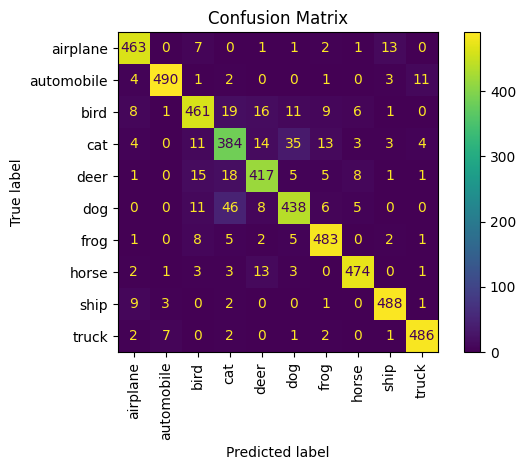

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model_nest.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device='cuda')
        labels = labels.to(device='cuda')

        logits = model_nest(images)
        predictions = logits.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=val_dataset.dataset.dataset.classes
)

disp.plot(
    xticks_rotation='vertical',
    values_format='d'
)

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [25]:
test_dataset = ProgressiveDataset(test_dataset)
test_loader = DataLoader(test_dataset, 32, False)

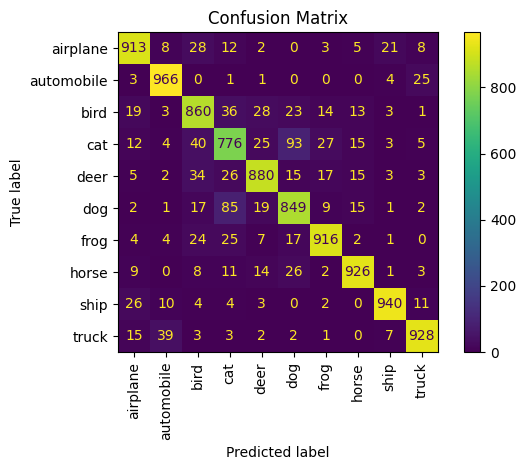

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model_nest.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device='cuda')
        labels = labels.to(device='cuda')

        logits = model_nest(images)
        predictions = logits.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.dataset.classes
)

disp.plot(
    xticks_rotation='vertical',
    values_format='d'
)

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

# Experimental heads

In [12]:
class RegressiveDim(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=1, stride=1, padding=0, bias=False):
        super().__init__()
        self.linear = nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=bias)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.LeakyReLU(0.1)
    def forward(self,x):
        x = self.linear(x)
        x = self.bn(x)
        x = self.relu(x)
        return x

In [17]:
class DualKernelCNNHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1 = DualKernelResidualCNN(3, 16, 3, 3, 5, 1, 1, 1, 1, 2)
        self.block2 = DualKernelResidualCNN(32, 32, 1, 3, 5, 1, 1, 0, 1, 2, False)
        self.block3 = DualKernelResidualCNN(32, 32, 3, 3, 5, 1, 1, 1, 1, 2)
        self.block4 = DualKernelResidualCNN(64, 64, 3, 3, 5, 2, 1, 1, 1, 2)
        self.block5 = DualKernelResidualCNN(128, 128, 1, 3, 5, 1, 1, 0, 1, 2, False)
        self.block6 = DualKernelResidualCNN(128, 128, 3, 3, 5, 1, 1, 1, 1, 2)
        self.block7 = DualKernelResidualCNN(256, 256, 3, 3, 3, 2, 1, 1, 1, 1)
        self.block8 = DualKernelResidualCNN(512, 512, 3, 3, 3, 2, 1, 1, 1, 1)
        self.block9 = DualKernelResidualCNN(1024, 1024, 1, 3, 3, 1, 1, 0, 1, 1, False)
        self.linear1 = RegressiveDim(1024, 1024 - 256)
        self.linear2 = RegressiveDim(1024-256, 512)
        self.linear3 = RegressiveDim(512, 256)
        self.linear4 = RegressiveDim(256,128)
        self.linear5 = RegressiveDim(128,10)
        self.gap = nn.AdaptiveAvgPool2d((1,1))
        self.shortcut_linear = nn.Linear(1024, 10)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = self.block6(x)
        x = self.block7(x)
        x = self.block8(x)
        x = self.block9(x)
        shortcut = x
        shortcut = self.gap(shortcut)
        shortcut = shortcut.squeeze(-1).squeeze(-1)
        shortcut = self.shortcut_linear(shortcut)
        x = self.linear1(x)
        x = self.linear2(x)
        x = self.linear3(x)
        x = self.linear4(x)
        x = self.linear5(x)
        x = self.gap(x)
        x = x.squeeze(-1).squeeze(-1)
        x = x+shortcut
        return x

In [36]:
num_epochs = 30

augment = ProgressiveDataAugmentation(15, 0.2, 0.2, 0.2, 0.1, 0.2, 0.5)

train_dataset_head = ProgressiveDataset(train_dataset, augment)

train_loader_head = DataLoader(train_dataset_head, 128, True,)

val_dataset_head = ProgressiveDataset(val_dataset)

val_loader_head = DataLoader(val_dataset_head, 128, False)

model_head = DualKernelCNNHead().to(device='cuda')

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model_head.parameters(),lr=0.001)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=int(num_epochs),
    eta_min=5e-5,
)


In [38]:
num_epochs = 30

augment = RegressiveAugmantation(30, 0.4, 0.4, 0.4, 0.2, 0.3, 0.5)

train_dataset_head = ProgressiveDataset(train_dataset, augment)

train_loader_head = DataLoader(train_dataset_head, 128, True,)

optimizer = torch.optim.AdamW(model_head.parameters(),lr=0.0001)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=int(num_epochs),
    eta_min=1e-5,
)


In [41]:
print(train_dataset_head.__dict__)
train_loss = {}
train_accuracy = {}

val_loss = {}
val_accuracy = {}

best_score = 10

print(f"allocated: {torch.cuda.memory_allocated()/1024**3:.2f} GB")
print(f"reserved:  {torch.cuda.memory_reserved()/1024**3:.2f} GB")

for epoch in range(num_epochs):
    train_loss[epoch]=[]
    train_accuracy[epoch]=[]
    val_loss[epoch]=[]
    val_accuracy[epoch]=[]
    augment.set_epoch(epoch+1)
    model_head.train()
    start_time = time.time()
    for step, (images, labels) in enumerate(train_loader_head, 1):

        images = images.to(device='cuda')
        labels = labels.to(device='cuda')

        optimizer.zero_grad()

        logits = model_head(images)

        loss = criterion(logits, labels)
        

        loss.backward()

        optimizer.step()

        if step % 50 == 0:
            train_loss[epoch].append(loss.item())
            predictions = logits.argmax(dim=1)
            train_correct = (predictions == labels).float().mean().item()
            train_accuracy[epoch].append(train_correct)



    model_head.eval()

    with torch.no_grad():
        for step, (images, labels) in enumerate(val_loader_head, 1):
            images = images.to(device='cuda')
            labels = labels.to(device='cuda')

            logits = model_head(images)
            loss = criterion(logits, labels)
            val_loss[epoch].append(loss.item())
            predictions = logits.argmax(dim=1)
            val_correct = (predictions == labels).float().mean().item()
            val_accuracy[epoch].append(val_correct)
        epoch_val_loss = np.mean(val_loss[epoch])
        if epoch_val_loss < best_score:
            best_score = epoch_val_loss
            torch.save({
            'epoch': epoch,
            'model_state_dict': model_head.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'train_loss': train_loss,
            'train_accuracy': train_accuracy,
            'val_loss': val_loss,
            'val_accuracy': val_accuracy,},
            f'model_head_checkpoint_3_{epoch}.pt')

    scheduler.step()
    epoch_time = time.time() - start_time
    torch.save({
    'epoch': epoch,
    'model_state_dict': model_head.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'scheduler_state_dict': scheduler.state_dict(),

    'train_loss': train_loss,
    'train_accuracy': train_accuracy,
    'val_loss': val_loss,
    'val_accuracy': val_accuracy,},
    'model_head_checkpoint_3.pt')

    print(f"Epoch: {epoch + 1}, train_loss: {np.mean(train_loss[epoch])}, accuracy: {np.mean(train_accuracy[epoch])} LR: {optimizer.param_groups[0]['lr']}")
    print(f"Epoch: {epoch +1}, Val_loss: {np.mean(val_loss[epoch])}, val_accuracy: {np.mean(val_accuracy[epoch])}, epoch time: {epoch_time}")

{'dataset': <torch.utils.data.dataset.Subset object at 0x000002E72A563A10>, 'augmentation': <__main__.RegressiveAugmantation object at 0x000002E7F5EF1040>}
allocated: 0.51 GB
reserved:  2.56 GB
Epoch: 1, train_loss: 0.322990928377424, accuracy: 0.8872767857142857 LR: 9.97534852915723e-05
Epoch: 1, Val_loss: 0.37029094705358145, val_accuracy: 0.8927734375, epoch time: 134.61417365074158
Epoch: 2, train_loss: 0.3390338250568935, accuracy: 0.9017857142857143 LR: 9.901664203302126e-05
Epoch: 2, Val_loss: 0.3603259431954939, val_accuracy: 0.89375, epoch time: 126.59035038948059
Epoch: 3, train_loss: 0.27841631429536, accuracy: 0.9095982142857143 LR: 9.779754323328192e-05
Epoch: 3, Val_loss: 0.3365209818817675, val_accuracy: 0.9029296875, epoch time: 123.10940861701965
Epoch: 4, train_loss: 0.2536546545369284, accuracy: 0.8973214285714286 LR: 9.610954559391703e-05
Epoch: 4, Val_loss: 0.3602279898244888, val_accuracy: 0.896484375, epoch time: 113.73589992523193
Epoch: 5, train_loss: 0.2745113

KeyboardInterrupt: 

### Dual-Kernel CNN with the Experimental Classification Head

The experimental classification head was evaluated with the Dual-Kernel CNN. By epoch 24, the model reached a validation accuracy of 91.86%, outperforming both the same architecture without the experimental head and the Dual-Kernel ResNest model in my experiments.

These results support the hypothesis that gradually reducing the channel dimensions through convolutional layers can be beneficial for classification. The experimental head preserves the original GAP + Linear path while adding a second path that transforms spatial features before global average pooling. The outputs of both paths are then combined to produce the final class scores.

The training logs also show a widening gap between training and validation performance. By epoch 24, training accuracy had reached 99.55%, while validation accuracy was 91.86%. Validation loss increased during the later epochs, indicating that the model was fitting the training data very closely, even as validation accuracy continued to improve slightly.

Overall, the experiment suggests that the convolutional classification path improved the model's validation performance, although the growing train–validation gap indicates that overfitting remained a challenge.

# Dual Nest + head + attention


In [13]:
class SpatialAttention(nn.Module):
    def __init__(self, channels, head=4):
        super().__init__()

        assert channels & head == 0

        self.norm = nn.LayerNorm(channels)

        self.attention = nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=head,
            batch_first=True
        )

        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        B, C, H, W = x.shape
        x_tokens = x.flatten(2).transpose(1,2)

        residual = x_tokens

        x_tokens = self.norm(x_tokens)
        x_tokens, _ = self.attention(
            x_tokens,
            x_tokens,
            x_tokens
        )

        x_tokens = residual + self.gamma * x_tokens

        x = x_tokens.transpose(1,2).reshape(B,C,H,W)

        return x


In [14]:
class AttentionDualKernelResidualCNN(nn.Module):
    def __init__ (self, in_channels, branch_channels ,kernel_in, kernel_size_1, kernel_size_2, stride_in, stride, padding_in, padding_1, padding_2, head = 4, is_expanded=True, attention=False):
        super().__init__()

        out_channels = branch_channels if is_expanded else branch_channels//2
        self.conv_in = nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=kernel_in, stride=stride_in, padding=padding_in, bias=False)
        self.conv_1 = nn.Conv2d(in_channels=out_channels, out_channels=out_channels, kernel_size=kernel_size_1, stride=stride, padding=padding_1, bias = False)
        self.conv_2 = nn.Conv2d(in_channels=out_channels, out_channels=out_channels, kernel_size=kernel_size_1, stride=stride, padding=padding_1, bias = False)
        self.dual_conv_1 = nn.Conv2d(in_channels=out_channels, out_channels=out_channels, kernel_size=kernel_size_2, stride=stride, padding=padding_2, bias=False)
        self.dual_conv_2 = nn.Conv2d(in_channels=out_channels, out_channels=out_channels, kernel_size=kernel_size_2, stride=stride, padding=padding_2, bias = False)
        self.bn_in = nn.BatchNorm2d(out_channels)
        self.bn_1 = nn.BatchNorm2d(out_channels)
        self.bn_2 = nn.BatchNorm2d(out_channels)
        self.dual_bn_1 = nn.BatchNorm2d(out_channels)
        self.dual_bn_2 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()
        self.attention = attention
        if attention:
            self.attention_l = SpatialAttention(branch_channels, head=head)
            self.attention_r = SpatialAttention(branch_channels, head=head)
    def forward(self, x):

        x = self.conv_in(x)
        x = self.bn_in(x)
        shortcut = x
        x = self.relu(x)
        x_l = self.conv_1(x)
        x_l = self.bn_1(x_l)
        x_l = self.relu(x_l)
        x_l = self.conv_2(x_l)
        x_l = self.bn_2(x_l)
        x_l = x_l + shortcut
        x_l = self.relu(x_l)
        if self.attention:
            x_l = self.attention_l(x_l)
        x_p = self.dual_conv_1(x)
        x_p = self.dual_bn_1(x_p)
        x_p = self.relu(x_p)
        x_p = self.dual_conv_2(x_p)
        x_p = self.dual_bn_2(x_p)
        x_p = x_p + shortcut
        x_p = self.relu(x_p)
        if self.attention:
            x_p = self.attention_r(x_p)
        x = torch.cat((x_l, x_p), dim=1)
        x = self.relu(x)
        return x        


In [15]:
class DualKernelResNest(nn.Module):
    def __init__(self, first_channel, in_channels, branch_channels ,kernel_in, kernel_size_1, kernel_size_2, stride_in, stride, padding_in, padding_1, padding_2, is_expanded=False, final_expand=False):
        super().__init__()
        self.block1 = nn.Conv2d(in_channels=first_channel, out_channels=branch_channels, kernel_size=kernel_size_1, stride=stride_in, padding=padding_1)
        self.block1_bn = nn.BatchNorm2d(branch_channels)
        self.l_l_dual_1 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.l_l_dual_2 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.l_r_dual_1 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.l_r_dual_2 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.r_l_dual_1 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.r_l_dual_2 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.r_r_dual_1 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.r_r_dual_2 = DualKernelResidualCNN(in_channels=in_channels, branch_channels=branch_channels, kernel_in=kernel_in,kernel_size_1=kernel_size_1, kernel_size_2=kernel_size_2, stride_in=stride, stride=stride, padding_in=padding_in, padding_1=padding_1, padding_2=padding_2, is_expanded=is_expanded)
        self.block_l = nn.Conv2d(in_channels=branch_channels*2, out_channels=branch_channels,kernel_size=1, stride=1, padding=0, bias=False)
        self.bn_block_l = nn.BatchNorm2d(branch_channels)
        self.block_r = nn.Conv2d(in_channels=branch_channels*2, out_channels=branch_channels, kernel_size=1, stride=1, padding=0, bias=False)
        self.bn_block_r = nn.BatchNorm2d(branch_channels)
        self.final_block = nn.Conv2d(in_channels=branch_channels*2, out_channels=branch_channels, kernel_size=1, stride=1, padding=0, bias=False)
        self.bn_final_block = nn.BatchNorm2d(branch_channels)
        self.relu = nn.ReLU()
        self.final_expand = final_expand

    def forward(self,x):
        x = self.block1(x)
        x = self.block1_bn(x)
        shortcut = x
        x = self.relu(x)
        x_l_l = self.l_l_dual_1(x)
        x_l_l = self.l_l_dual_2(x_l_l)
        x_l_r = self.l_r_dual_1(x)
        x_l_r = self.l_r_dual_2(x_l_r)
        x_l = torch.cat((x_l_l, x_l_r), dim=1)
        x_l = self.block_l(x_l)
        x_l = self.bn_block_l(x_l)
        x_l = x_l + shortcut
        x_l = self.relu(x_l)
        x_r_l = self.r_l_dual_1(x)
        x_r_l = self.r_l_dual_2(x_r_l)
        x_r_r = self.r_r_dual_1(x)
        x_r_r = self.r_r_dual_2(x_r_r)
        x_r = torch.cat((x_r_l, x_r_r), dim=1)
        x_r = self.block_r(x_r)
        x_r = self.bn_block_r(x_r)
        x_r = x_r + shortcut
        x = torch.cat((x_l, x_r), dim=1)
        if self.final_expand:
            return x
        else:
            x = self.final_block(x)
            x = self.bn_final_block(x)
            x = self.relu(x)
            return x

In [16]:
class RegressiveDim(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=1, stride=1, padding=0, bias=False):
        super().__init__()
        self.linear = nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=bias)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.LeakyReLU(0.1)
    def forward(self,x):
        x = self.linear(x)
        x = self.bn(x)
        x = self.relu(x)
        return x

In [17]:
class AttentionNestDualCNNHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1 = DualKernelResNest(3, 32, 32, 3, 3, 5, 1, 1, 1, 1, 2)
        self.block2 = DualKernelResNest(32, 32, 32, 3, 3, 5, 1, 1, 1, 1, 2, False, True)
        self.block3 = DualKernelResNest(64, 64, 64, 3, 3, 5,1,1,1,1,2)
        self.block4 = DualKernelResNest(64, 64, 64, 3, 3, 5, 1, 1, 1, 1, 2, False, True)
        self.block5 = DualKernelResNest(128, 128, 128, 3,3,5,2,1,1,1,2,)
        self.block6 = DualKernelResNest(128,128,128,3,3,5,2,1,1,1,2,False,True)
        self.block7 = AttentionDualKernelResidualCNN(256, 256,3,3,3,1,1,1,1,1,4,True,True)
        self.block8 = AttentionDualKernelResidualCNN(512, 512, 3, 3, 3,2,1,1,1,1,4,True,True)
        self.block9 = DualKernelResidualCNN(1024,1024,3,3,3,1,1,1,1,1,False)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.linear = nn.Linear(1024,10)
        self.conv_linear1 = RegressiveDim(1024, 1024-256)
        self.conv_linear2 = RegressiveDim(1024-256,512)
        self.conv_linear3 = RegressiveDim(512,256)
        self.conv_linear4 = RegressiveDim(256,128)
        self.conv_linear5 = RegressiveDim(128,64)
        self.conv_linear6 = RegressiveDim(64,10)
    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = self.block6(x)
        x = self.block7(x)
        x = self.block8(x)
        x = self.block9(x)
        shortcut = x
        shortcut = self.conv_linear1(shortcut)
        shortcut = self.conv_linear2(shortcut)
        shortcut = self.conv_linear3(shortcut)
        shortcut = self.conv_linear4(shortcut)
        shortcut = self.conv_linear5(shortcut)
        shortcut = self.conv_linear6(shortcut)
        shortcut = self.gap(shortcut)
        shortcut = shortcut.squeeze(-1).squeeze(-1)
        x = self.gap(x)
        x = x.squeeze(-1).squeeze(-1)
        x = self.linear(x)
        x = x+shortcut
        return x


In [23]:
num_epochs = 30

augment = RegressiveAugmantation(
    30,
    0.4, 0.4, 0.4,
    0.15,
    0.2,
    0.5
)

train_dataset = ProgressiveDataset(
    train_dataset,
    augment
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

model_nest_attention = AttentionNestDualCNNHead(
).to(device="cuda")

optimizer = torch.optim.AdamW(
    model_nest_attention.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=num_epochs,
    eta_min=1e-5
)

In [24]:
criterion = nn.CrossEntropyLoss()

In [26]:

train_loss = {}
train_accuracy = {}

val_loss = {}
val_accuracy = {}

best_score = 10

print(f"allocated: {torch.cuda.memory_allocated()/1024**3:.2f} GB")
print(f"reserved:  {torch.cuda.memory_reserved()/1024**3:.2f} GB")

for epoch in range(num_epochs):
    train_loss[epoch]=[]
    train_accuracy[epoch]=[]
    val_loss[epoch]=[]
    val_accuracy[epoch]=[]
    augment.set_epoch(epoch+1)
    model_nest_attention.train()
    start_time = time.time()
    for step, (images, labels) in enumerate(train_loader, 1):

        images = images.to(device='cuda')
        labels = labels.to(device='cuda')

        optimizer.zero_grad()

        logits = model_nest_attention(images)

        loss = criterion(logits, labels)
        

        loss.backward()

        optimizer.step()

        if step % 50 == 0:
            train_loss[epoch].append(loss.item())
            predictions = logits.argmax(dim=1)
            train_correct = (predictions == labels).float().mean().item()
            train_accuracy[epoch].append(train_correct)



    model_nest_attention.eval()

    with torch.no_grad():
        for step, (images, labels) in enumerate(val_loader, 1):
            images = images.to(device='cuda')
            labels = labels.to(device='cuda')

            logits = model_nest_attention(images)
            loss = criterion(logits, labels)
            val_loss[epoch].append(loss.item())
            predictions = logits.argmax(dim=1)
            val_correct = (predictions == labels).float().mean().item()
            val_accuracy[epoch].append(val_correct)
        epoch_val_loss = np.mean(val_loss[epoch])
        if epoch_val_loss < best_score:
            best_score = epoch_val_loss
            torch.save({
            'epoch': epoch,
            'model_state_dict': model_nest_attention.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'train_loss': train_loss,
            'train_accuracy': train_accuracy,
            'val_loss': val_loss,
            'val_accuracy': val_accuracy,},
            f'model_nest_attebtion{epoch}.pt')

    scheduler.step()
    epoch_time = time.time() - start_time
    torch.save({
    'epoch': epoch,
    'model_state_dict': model_nest_attention.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'scheduler_state_dict': scheduler.state_dict(),

    'train_loss': train_loss,
    'train_accuracy': train_accuracy,
    'val_loss': val_loss,
    'val_accuracy': val_accuracy,},
    'model_nest_attention.pt')

    print(f"Epoch: {epoch + 1}, train_loss: {np.mean(train_loss[epoch])}, accuracy: {np.mean(train_accuracy[epoch])} LR: {optimizer.param_groups[0]['lr']}")
    print(f"Epoch: {epoch +1}, Val_loss: {np.mean(val_loss[epoch])}, val_accuracy: {np.mean(val_accuracy[epoch])}, epoch time: {epoch_time}")

allocated: 0.63 GB
reserved:  2.63 GB
Epoch: 1, train_loss: 1.5578487856047494, accuracy: 0.45200892857142855 LR: 0.0009972883382072953
Epoch: 1, Val_loss: 1.5490240544080733, val_accuracy: 0.4470703125, epoch time: 569.913491487503
Epoch: 2, train_loss: 1.277979999780655, accuracy: 0.5591517857142857 LR: 0.0009891830623632338
Epoch: 2, Val_loss: 1.206907593086362, val_accuracy: 0.5853515625, epoch time: 578.7998747825623
Epoch: 3, train_loss: 1.1362880298069544, accuracy: 0.5993303571428571 LR: 0.0009757729755661011
Epoch: 3, Val_loss: 0.9290464475750924, val_accuracy: 0.66953125, epoch time: 573.3125576972961
Epoch: 4, train_loss: 0.9991402221577508, accuracy: 0.6484375 LR: 0.0009572050015330874
Epoch: 4, Val_loss: 0.868808637559414, val_accuracy: 0.6892578125, epoch time: 572.5754749774933
Epoch: 5, train_loss: 0.7955069339701107, accuracy: 0.7131696428571429 LR: 0.0009336825748732973
Epoch: 5, Val_loss: 0.8227220246568322, val_accuracy: 0.7171875, epoch time: 572.2738914489746
Epoc

In [18]:
class AttentionDualKernelCNNHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1 = AttentionDualKernelResidualCNN(3, 16, 3, 3, 5, 1, 1, 1, 1, 2,)
        self.block2 = AttentionDualKernelResidualCNN(32, 32, 1, 3, 5, 1, 1, 0, 1, 2, 4, False)
        self.block3 = AttentionDualKernelResidualCNN(32, 32, 3, 3, 5, 1, 1, 1, 1, 2, 4, True, True,)
        self.block4 = AttentionDualKernelResidualCNN(64, 64, 3, 3, 5, 2, 1, 1, 1, 2, 4, True, True)
        self.block5 = AttentionDualKernelResidualCNN(128, 128, 1, 3, 5, 1, 1, 0, 1, 2, 4, False)
        self.block6 = AttentionDualKernelResidualCNN(128, 128, 3, 3, 5, 1, 1, 1, 1, 2, 4, True, True)
        self.block7 = AttentionDualKernelResidualCNN(256, 256, 3, 3, 3, 2, 1, 1, 1, 1, 4, True, True)
        self.block8 = AttentionDualKernelResidualCNN(512, 512, 3, 3, 3, 2, 1, 1, 1, 1)
        self.block9 = AttentionDualKernelResidualCNN(1024, 1024, 1, 3, 3, 1, 1, 0, 1, 1, 4, False)
        self.linear1 = RegressiveDim(1024, 1024 - 256)
        self.linear2 = RegressiveDim(1024-256, 512)
        self.linear3 = RegressiveDim(512, 256)
        self.linear4 = RegressiveDim(256,128)
        self.linear5 = RegressiveDim(128,10)
        self.gap = nn.AdaptiveAvgPool2d((1,1))
        self.shortcut_linear = nn.Linear(1024, 10)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = self.block6(x)
        x = self.block7(x)
        x = self.block8(x)
        x = self.block9(x)
        shortcut = x
        shortcut = self.gap(shortcut)
        shortcut = shortcut.squeeze(-1).squeeze(-1)
        shortcut = self.shortcut_linear(shortcut)
        x = self.linear1(x)
        x = self.linear2(x)
        x = self.linear3(x)
        x = self.linear4(x)
        x = self.linear5(x)
        x = self.gap(x)
        x = x.squeeze(-1).squeeze(-1)
        x = x+shortcut
        return x

In [19]:
num_epochs = 30

augment = ProgressiveDataAugmentation(
    30,
    0.4, 0.4, 0.4,
    0.15,
    0.2,
    0.5
)

train_dataset = ProgressiveDataset(
    train_dataset,
    augment
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)


val_dataset = ProgressiveDataset(val_dataset)

val_loader = DataLoader(val_dataset, 32, False)

criterion = nn.CrossEntropyLoss()

model_dual_attention = AttentionDualKernelCNNHead(
).to(device="cuda")

optimizer = torch.optim.AdamW(
    model_dual_attention.parameters(),
    lr=1e-3,
    weight_decay=5e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=num_epochs,
    eta_min=1e-5
)

In [ ]:
checkpoint = torch.load(
    'model_nest_attebtion_13_best.pt',
    map_location='cuda'
)

# model
model_dual_attention = AttentionDualKernelCNNHead().to('cuda')

model_dual_attention.load_state_dict(
    checkpoint['model_state_dict']
)

# optimizer
optimizer = torch.optim.AdamW(
    model_dual_attention.parameters(),
    lr=1e-3,
    weight_decay=5e-4
)

optimizer.load_state_dict(
    checkpoint['optimizer_state_dict']
)

# scheduler
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=30,
    eta_min=1e-5
)

scheduler.load_state_dict(
    checkpoint['scheduler_state_dict']
)

start_epoch = checkpoint['epoch'] + 1

print(f"Wczytano checkpoint z epoki: {checkpoint['epoch'] + 1}")
print(f"Kontynuacja od epoki: {start_epoch}")
print(f"LR: {optimizer.param_groups[0]['lr']}")

In [21]:
num_epochs = 15

In [19]:
augment = RegressiveAugmantation(15, 0.4, 0.4, 0.4, 0.000001, 0.3, 0.7)

checkpoint = torch.load(
    'model_nest_attebtion_20_best.pt',
    map_location='cuda'
)


model_dual_attention = AttentionDualKernelCNNHead().to('cuda')

model_dual_attention.load_state_dict(
    checkpoint['model_state_dict']
)

train_dataset = ProgressiveDataset(train_dataset, augment)

train_loader = DataLoader(train_dataset, 32, True)


val_dataset = ProgressiveDataset(val_dataset)

val_loader = DataLoader(val_dataset, 32, False)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model_dual_attention.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

optimizer.load_state_dict(
    checkpoint['optimizer_state_dict']
)
for param_group in optimizer.param_groups:
    param_group['lr'] = 1e-4

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=15,
    eta_min=1e-5
)

In [20]:
del model_dual_attention
del optimizer
del scheduler
torch.cuda.empty_cache()

In [3]:
import gc
gc.collect()
torch.cuda.empty_cache()

print(torch.cuda.memory_allocated() / 1024**3)
print(torch.cuda.memory_reserved() / 1024**3)

0.0
0.0


In [22]:

train_loss = {}
train_accuracy = {}

val_loss = {}
val_accuracy = {}

best_score = 0.374165

print(f"allocated: {torch.cuda.memory_allocated()/1024**3:.2f} GB")
print(f"reserved:  {torch.cuda.memory_reserved()/1024**3:.2f} GB")

for epoch in range(num_epochs):
    train_loss[epoch]=[]
    train_accuracy[epoch]=[]
    val_loss[epoch]=[]
    val_accuracy[epoch]=[]
    augment.set_epoch(epoch+1)
    model_dual_attention.train()
    start_time = time.time()
    for step, (images, labels) in enumerate(train_loader, 1):

        images = images.to(device='cuda')
        labels = labels.to(device='cuda')

        optimizer.zero_grad()

        logits = model_dual_attention(images)

        loss = criterion(logits, labels)
        

        loss.backward()

        optimizer.step()

        if step % 50 == 0:
            train_loss[epoch].append(loss.item())
            predictions = logits.argmax(dim=1)
            train_correct = (predictions == labels).float().mean().item()
            train_accuracy[epoch].append(train_correct)



    model_dual_attention.eval()

    with torch.no_grad():
        for step, (images, labels) in enumerate(val_loader, 1):
            images = images.to(device='cuda')
            labels = labels.to(device='cuda')

            logits = model_dual_attention(images)
            loss = criterion(logits, labels)
            val_loss[epoch].append(loss.item())
            predictions = logits.argmax(dim=1)
            val_correct = (predictions == labels).float().mean().item()
            val_accuracy[epoch].append(val_correct)
        epoch_val_loss = np.mean(val_loss[epoch])
        if epoch_val_loss < best_score:
            best_score = epoch_val_loss
            torch.save({
            'epoch': epoch,
            'model_state_dict': model_dual_attention.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'train_loss': train_loss,
            'train_accuracy': train_accuracy,
            'val_loss': val_loss,
            'val_accuracy': val_accuracy,},
            f'model_nest_attebtion_{epoch}_best.pt')

    scheduler.step()
    epoch_time = time.time() - start_time
    torch.save({
    'epoch': epoch,
    'model_state_dict': model_dual_attention.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'scheduler_state_dict': scheduler.state_dict(),

    'train_loss': train_loss,
    'train_accuracy': train_accuracy,
    'val_loss': val_loss,
    'val_accuracy': val_accuracy,},
    'model_nest_attention.pt')

    for name, module in model_dual_attention.named_modules():
        if isinstance(module, SpatialAttention):
            print(name, module.gamma.item())
    print(f"Epoch: {epoch + 1}, train_loss: {np.mean(train_loss[epoch])}, accuracy: {np.mean(train_accuracy[epoch])} LR: {optimizer.param_groups[0]['lr']}")
    print(f"Epoch: {epoch +1}, Val_loss: {np.mean(val_loss[epoch])}, val_accuracy: {np.mean(val_accuracy[epoch])}, epoch time: {epoch_time}")

allocated: 0.43 GB
reserved:  0.46 GB
block3.attention_l -0.2531265318393707
block3.attention_r -0.2016916424036026
block4.attention_l -0.06595273315906525
block4.attention_r -0.10821483284235
block6.attention_l -0.01345271896570921
block6.attention_r 0.010540327057242393
block7.attention_l 0.0005455505452118814
block7.attention_r -0.0014596463879570365
Epoch: 1, train_loss: 0.40240950509905815, accuracy: 0.8549107142857143 LR: 9.901664203302126e-05
Epoch: 1, Val_loss: 0.3483034302213579, val_accuracy: 0.8913216560509554, epoch time: 466.35870718955994
block3.attention_l -0.25675275921821594
block3.attention_r -0.19956213235855103
block4.attention_l -0.06625528633594513
block4.attention_r -0.10748160630464554
block6.attention_l -0.015288552269339561
block6.attention_r 0.01077134907245636
block7.attention_l 0.0036343655083328485
block7.attention_r -0.0013464728835970163
Epoch: 2, train_loss: 0.2967211428497519, accuracy: 0.8995535714285714 LR: 9.610954559391703e-05
Epoch: 2, Val_loss: 0

KeyboardInterrupt: 